POST GERNATOR FOR SOCIAL MEDIA

In [2]:
# ALERT: ALL imports
from langgraph.graph import StateGraph, START,END
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Literal, Annotated
import operator
from langchain_core.messages import SystemMessage, HumanMessage
from pydantic import BaseModel,Field

In [3]:
load_dotenv()

True

In [4]:
# initailize Llm
generator_llm = ChatGoogleGenerativeAI(model='gemini-3.6-flash')
evaluator_llm = ChatGoogleGenerativeAI(model='gemini-3.6-flash')
optimizer_llm = ChatGoogleGenerativeAI(model='gemini-3.6-flash')

In [5]:
#State
class TweetState(TypedDict):
    topic:str
    tweet:str
    Platfrom:str
    evaluation:Literal["approved", "needs_improvement"]
    feedback:str
    iteration:int
    max_iteration:int
    

In [6]:
# Strcutured ouput format for evalutor
class TweetEvaluation(BaseModel):
    evaluation: Literal['approved', 'need_improvement'] = Field(..., description='final evaluation result.')
    feedback: str =Field(..., description="feedback for Socail Medai Post")

In [7]:
structured_evaluator_llm = evaluator_llm.with_structured_output(TweetEvaluation)

In [8]:
#TASK Gernator

def gernerator(state:TweetState)->TweetState:
    """It Take The TOPIC  and Gernate the Post """
    #prompt
    message= [
        SystemMessage(content="You are a Professional socail media Post Writer For different Platform"),
        HumanMessage(f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}" for this Platform:"{state['Platfrom']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
        """)
    ]

    ### send to  gernator llm
    response=generator_llm.invoke(message).content
    return {'tweet': response}

    

In [9]:
# Evaluator
def evaluator(state:TweetState)->TweetState:
    """It evaluate the tweet by two things apporved needs imporvement"""
    #prompt
    message =[
        SystemMessage(content="You are a ruthless, no-laugh-given Social Media critic. You evaluate tweets/Post based on humor, originality, virality, and tweet/Post format."),
        HumanMessage(content=f"""
        Evaluate the following tweet:

        Tweet: "{state['tweet']}"

se the criteria below to evaluate the tweet:

1. Originality – Is this fresh, or have you seen it a hundred times before?  
2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
3. Punchiness – Is it short, sharp, and scroll-stopping?  
4. Virality Potential – Would people retweet or share it?  
5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"  
- feedback: One paragraph explaining the strengths and weaknesses 
""")
    ]

    #response
    response= structured_evaluator_llm.invoke(message)
    #state return

    return { 'evaluation': response. evaluation, 'feedback': response.feedback}   

In [10]:
# optimizer
def optimizer(state:TweetState)-> TweetState:
    """It it the tweet/Post after evaltuion if need_improvements"""
    #prompt
    message=[
        SystemMessage(content='You Punch tweets/Post for virality and humor based on given feedback'),
        HumanMessage(f"""
             Imporve The Post based on this feedback:
             "{state['feedback']}"
             Topic: "{state['topic']}"
             Platform:"{state['Platfrom']}"
             Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet/Post. Avoid Q&A style and stay under 280 characters.
 
        """)
    ]

    #response
    response= optimizer_llm.invoke(message).content
    iteration=state['iteration'] + 1

    return {'tweet':response, 'iteration':iteration}

In [11]:
# router

def router_evaluation(state:TweetState)->TweetState:
    """IT route the evaltion and optimization"""
    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return "needs_improvement"
    

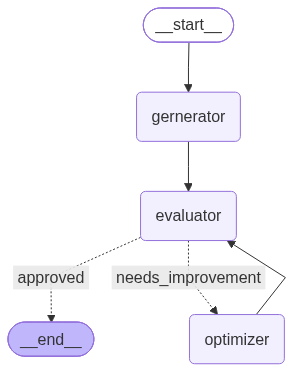

In [12]:
# create graph
graph =StateGraph(TweetState)

graph.add_node("gernerator", gernerator)
graph.add_node('evaluator',evaluator)
graph.add_node('optimizer',optimizer)

graph.add_edge(START, 'gernerator')
graph.add_edge('gernerator','evaluator')
graph.add_conditional_edges('evaluator', router_evaluation,{'approved':END, 'needs_improvement':"optimizer"} )
graph.add_edge('optimizer','evaluator')

workflow=graph.compile()
workflow

In [ ]:
initial_state = {
    "topic": "Future of ai",
    'Platfrom':"Linkedin",
    "iteration": 1,
    "max_iteration": 5
}

final_answer = workflow.invoke(initial_state)
print(final_answer).content